In [2]:
!pip install pandas numpy seaborn scikit-learn matplotlib


Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   --- ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load Titanic dataset
df = sns.load_dataset('titanic')

# Display first five rows
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [5]:
# Dataset information
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (891, 15)

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Data Types:
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [6]:
print("Before Handling Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Before Handling Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Total Missing Values: 869


In [7]:
# Select input features
X = df[['age', 'fare', 'sibsp', 'parch',
        'pclass', 'sex', 'embarked']]

# Select target variable
y = df['survived']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
    age     fare  sibsp  parch  pclass     sex embarked
0  22.0   7.2500      1      0       3    male        S
1  38.0  71.2833      1      0       1  female        C
2  26.0   7.9250      0      0       3  female        S
3  35.0  53.1000      1      0       1  female        S
4  35.0   8.0500      0      0       3    male        S

Target Variable:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 7)
Testing Data: (179, 7)


In [9]:
# Numerical and categorical columns
numerical_features = [
    'age', 'fare', 'sibsp', 'parch', 'pclass'
]

categorical_features = [
    'sex', 'embarked'
]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Feature engineering completed successfully!")

Feature engineering completed successfully!


In [10]:
# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Convert processed data into DataFrame
X_train_clean = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

print("Cleaned and Model-Ready Dataset:")
print(X_train_clean.head())

Cleaned and Model-Ready Dataset:
     num__age  num__fare  num__sibsp  num__parch  num__pclass  \
692 -0.081135   0.513812   -0.465084   -0.466183     0.829568   
481 -0.081135  -0.662563   -0.465084   -0.466183    -0.370945   
527 -0.081135   3.955399   -0.465084   -0.466183    -1.571457   
855 -0.887827  -0.467874   -0.465084    0.727782     0.829568   
801  0.110934  -0.115977    0.478335    0.727782    -0.370945   

     cat__sex_female  cat__sex_male  cat__embarked_C  cat__embarked_Q  \
692              0.0            1.0              0.0              0.0   
481              0.0            1.0              0.0              0.0   
527              0.0            1.0              0.0              0.0   
855              1.0            0.0              0.0              0.0   
801              1.0            0.0              0.0              0.0   

     cat__embarked_S  
692              1.0  
481              1.0  
527              1.0  
855              1.0  
801              1.0  

In [11]:
print("Missing Values After Preprocessing:",
      X_train_clean.isnull().sum().sum())

print("\nFinal Training Dataset Shape:",
      X_train_clean.shape)

print("\nFinal Testing Dataset Shape:",
      X_test_processed.shape)

print("\nAll numerical features are scaled and categorical features are encoded.")

Missing Values After Preprocessing: 0

Final Training Dataset Shape: (712, 10)

Final Testing Dataset Shape: (179, 10)

All numerical features are scaled and categorical features are encoded.


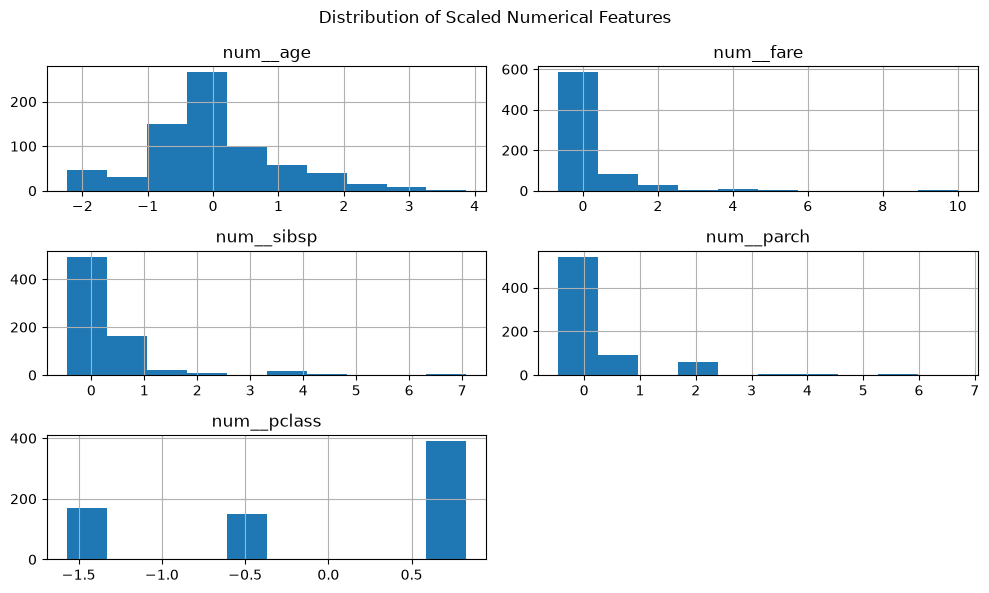

In [12]:
import matplotlib.pyplot as plt

X_train_clean.iloc[:, :5].hist(figsize=(10, 6))

plt.suptitle("Distribution of Scaled Numerical Features")
plt.tight_layout()
plt.show()

In [14]:
X_train_clean.to_csv("cleaned_titanic_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
